# Prepare model training data for Trastuzumab-scFv CDRH3 variants

Prepare sequences and measured scores for Trastuzumab-scFv CDRH3 variants, split the data into training, validation, and test sets, and write the files used by bVAE and pLM-bVAE.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load and prepare the data

In [2]:
# Load the data.
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
cdrh3_data = pd.read_csv(plm_data + 'raw_data\\cdrh3_data_clean.csv')

In [3]:
cdrh3_data

,seq,score,cdrh3_seq
0,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.816049,CSRWGGDGFYAMDYW
1,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.256693,CSRWGGPGFYAFDYW
2,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.741391,CSRWGGLGFYAFKYW
3,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.598910,CSRWLGLGFYAFDYW
4,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.292460,CSRWEGPGFYAFDYW
...,...,...,...
9586,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.998163,CSRWRSDFFYAMDYW
9587,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,3.004830,CSRWEILGFYAMDYW
9588,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.583998,CSRWELHGFYAMDYW
9589,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.861273,CSRWSADGFYAMDYW


In [4]:
# Count consecutive repeats in the CDRH3 sequences.
from collections import Counter
def count_consecutive_repeats(sequence):
    if not sequence:
        return 0
    count = 1
    max_count = 1
    for i in range(1, len(sequence)):
        if sequence[i] == sequence[i-1]:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 1
    return max_count

print(cdrh3_data['seq'].apply(count_consecutive_repeats).value_counts())

seq
4    9591
Name: count, dtype: int64


In [5]:
# Count CDRH3 sequences by length in ascending order.
cdrh3_data['cdrh3_seq'].apply(len).value_counts().sort_index()

cdrh3_seq
14      36
15    9491
16      59
17       4
18       1
Name: count, dtype: int64

## Random data split

### bVAE training data

In [6]:
# Shuffle the CDRH3 data.
cdrh3_data_shuffled = cdrh3_data.sample(frac=1, random_state=42).reset_index(drop=True)

# Split the shuffled data into training, validation, and test sets at a ratio of 0.8:0.1:0.1.
train_size = int(0.8 * len(cdrh3_data_shuffled))
dev_size = int(0.1 * len(cdrh3_data_shuffled))
cdrh3_train = cdrh3_data_shuffled[:train_size]
cdrh3_dev = cdrh3_data_shuffled[train_size:train_size + dev_size]
cdrh3_test = cdrh3_data_shuffled[train_size + dev_size:]

In [7]:
# Check the number of sequences in each split.
print(cdrh3_train.shape[0], cdrh3_dev.shape[0], cdrh3_test.shape[0])

7672 959 960


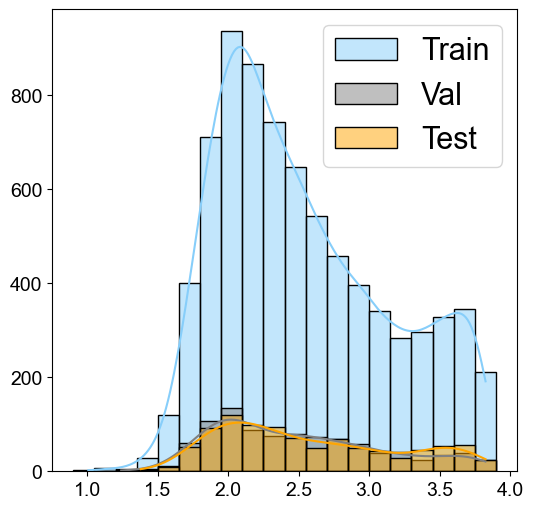

In [8]:
# Inspect the score distributions of the training, validation, and test sets.
plt.figure(figsize=(6, 6))

bin_width = 0.15

# Find the combined score range across the three splits.
all_scores = pd.concat([cdrh3_train["score"], cdrh3_dev["score"], cdrh3_test["score"]])

# Align histogram bin boundaries to multiples of the bin width.
bin_min = np.floor(all_scores.min() / bin_width) * bin_width
bin_max = np.ceil(all_scores.max() / bin_width) * bin_width

# Use common bins for the three splits.
common_bins = np.arange(bin_min, bin_max + bin_width, bin_width)

sns.histplot(cdrh3_train["score"], bins=common_bins, color="lightskyblue", kde=True, label="Train", alpha=0.5)
sns.histplot(cdrh3_dev["score"], bins=common_bins, color="gray", kde=True, label="Val", alpha=0.5)
sns.histplot(cdrh3_test["score"], bins=common_bins, color="orange", kde=True, label="Test", alpha=0.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel("")
plt.ylabel("")
plt.legend(fontsize=22)
plt.show()

In [9]:
# Extract the CDRH3 sequence column.
cdrh3_train_seq = cdrh3_train["cdrh3_seq"]
cdrh3_dev_seq = cdrh3_dev["cdrh3_seq"]
cdrh3_test_seq = cdrh3_test["cdrh3_seq"]

# Check for duplicate sequences within each split.
print(cdrh3_train_seq.shape[0], cdrh3_dev_seq.shape[0], cdrh3_test_seq.shape[0])

# Check for sequences shared between splits.
print(set(cdrh3_train_seq) & set(cdrh3_dev_seq), set(cdrh3_train_seq) & set(cdrh3_test_seq), set(cdrh3_dev_seq) & set(cdrh3_test_seq))

# Check the split sizes and proportions.
cdrh3_train_seq.shape[0] / cdrh3_data.shape[0], cdrh3_dev_seq.shape[0] / cdrh3_data.shape[0], cdrh3_test_seq.shape[0] / cdrh3_data.shape[0]

7672 959 960
set() set() set()


(0.7999165884683558, 0.09998957355854447, 0.10009383797309979)

In [10]:
# Insert spaces between residues in each sequence for the model input.
cdrh3_train_seq_spaced = cdrh3_train_seq.apply(lambda x: " ".join(list(x)))
cdrh3_dev_seq_spaced = cdrh3_dev_seq.apply(lambda x: " ".join(list(x)))
cdrh3_test_seq_spaced = cdrh3_test_seq.apply(lambda x: " ".join(list(x)))

In [11]:
cdrh3_train_seq_spaced

0       C S R Y G A N Y F Y A F A Y W
1       C S R W G F A G P Y A H D Y W
2       C S R W T G Y G F Y A F D Y W
3       C S R W E A M G P Y F F D Y W
4       C S R W P G N G P Y F Y D Y W
                    ...              
7667    C S R W L A D G P Y A F D Y W
7668    C S R W R G H G P Y A F D Y W
7669    C S R W G T G G F Y A Y D Y W
7670    C S R Y G W A Y C Y A Y A Y W
7671    C S R Y G A M G L Y A F S Y W
Name: cdrh3_seq, Length: 7672, dtype: object

In [ ]:
# Save the training, validation, and test splits.
cdrh3_train_seq_spaced.to_csv(plm_data + 'cdrh3\\bvae\\train.txt', sep="\t", index=False, header=False)
cdrh3_dev_seq_spaced.to_csv(plm_data + 'cdrh3\\bvae\\dev.txt', sep="\t", index=False, header=False)
cdrh3_test_seq_spaced.to_csv(plm_data + 'cdrh3\\bvae\\test.txt', sep="\t", index=False, header=False)

### bVAE training data

In [12]:
cdrh3_train

,seq,score,cdrh3_seq
0,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.163207,CSRYGANYFYAFAYW
1,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,3.722463,CSRWGFAGPYAHDYW
2,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.734662,CSRWTGYGFYAFDYW
3,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.074031,CSRWEAMGPYFFDYW
4,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.823971,CSRWPGNGPYFYDYW
...,...,...,...
7667,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.023558,CSRWLADGPYAFDYW
7668,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,2.581036,CSRWRGHGPYAFDYW
7669,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,1.960107,CSRWGTGGFYAYDYW
7670,EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLE...,3.563776,CSRYGWAYCYAYAYW


In [13]:
# Calculate the start and end positions of training CDRH3 regions in the full sequences.
cdrh3_train["region_start"] = [full.find(region) + 1 for full, region in zip(cdrh3_train['seq'], cdrh3_train['cdrh3_seq'])]
cdrh3_train["region_end"] = (cdrh3_train['region_start'] + cdrh3_train['cdrh3_seq'].str.len())

# Check that the training CDRH3 lengths match their start and end positions.
assert all(cdrh3_train["cdrh3_seq"].str.len() == (cdrh3_train["region_end"] - cdrh3_train["region_start"]))

# Calculate the start and end positions of validation CDRH3 regions in the full sequences.
cdrh3_dev["region_start"] = [full.find(region) + 1 for full, region in zip(cdrh3_dev['seq'], cdrh3_dev['cdrh3_seq'])]
cdrh3_dev["region_end"] = (cdrh3_dev['region_start'] + cdrh3_dev['cdrh3_seq'].str.len())

# Check that the validation CDRH3 lengths match their start and end positions.
assert all(cdrh3_dev["cdrh3_seq"].str.len() == (cdrh3_dev["region_end"] - cdrh3_dev["region_start"]))

# Calculate the start and end positions of test CDRH3 regions in the full sequences.
cdrh3_test["region_start"] = [full.find(region) + 1 for full, region in zip(cdrh3_test['seq'], cdrh3_test['cdrh3_seq'])]
cdrh3_test["region_end"] = (cdrh3_test['region_start'] + cdrh3_test['cdrh3_seq'].str.len())

# Check that the test CDRH3 lengths match their start and end positions.
assert all(cdrh3_test["cdrh3_seq"].str.len() == (cdrh3_test["region_end"] - cdrh3_test["region_start"]))

In [ ]:
# Reset the indices of the training, validation, and test data.
cdrh3_train = cdrh3_train.reset_index(drop=True)
cdrh3_dev = cdrh3_dev.reset_index(drop=True)
cdrh3_test = cdrh3_test.reset_index(drop=True)

# Save the residue indices of each training CDRH3 region as a NumPy array.
for i in range(len(cdrh3_train)):
    idx_array = np.arange(cdrh3_train['region_start'][i], cdrh3_train['region_end'][i])
    np.save(plm_data + f'cdrh3\\plm-bvae\\train\\indices\\{i}.idx.npy', idx_array)

# Save the residue indices of each validation CDRH3 region as a NumPy array.
for i in range(len(cdrh3_dev)):
    idx_array = np.arange(cdrh3_dev['region_start'][i], cdrh3_dev['region_end'][i])
    np.save(plm_data + f'cdrh3\\plm-bvae\\dev\\indices\\{i}.idx.npy', idx_array)

# Save the residue indices of each test CDRH3 region as a NumPy array.
for i in range(len(cdrh3_test)):
    idx_array = np.arange(cdrh3_test['region_start'][i], cdrh3_test['region_end'][i])
    np.save(plm_data + f'cdrh3\\plm-bvae\\test\\indices\\{i}.idx.npy', idx_array)

In [15]:
idx_array

array([ 96,  97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108,
       109, 110])

In [16]:
# Extract the sequence column.
cdrh3_train_full_seq = cdrh3_train["seq"]
cdrh3_dev_full_seq = cdrh3_dev["seq"]
cdrh3_test_full_seq = cdrh3_test["seq"]

# Check for duplicate sequences within each split.
print(cdrh3_train_full_seq.shape[0], cdrh3_dev_full_seq.shape[0], cdrh3_test_full_seq.shape[0])

# Check for sequences shared between splits.
print(set(cdrh3_train_full_seq) & set(cdrh3_dev_full_seq), set(cdrh3_train_full_seq) & set(cdrh3_test_full_seq), set(cdrh3_dev_full_seq) & set(cdrh3_test_full_seq))

# Check the split sizes and proportions.
cdrh3_train_full_seq.shape[0] / cdrh3_data.shape[0], cdrh3_dev_full_seq.shape[0] / cdrh3_data.shape[0], cdrh3_test_full_seq.shape[0] / cdrh3_data.shape[0]

7672 959 960
set() set() set()


(0.7999165884683558, 0.09998957355854447, 0.10009383797309979)

In [17]:
# Insert spaces between residues in each sequence for the model input.
cdrh3_train_full_seq_spaced = cdrh3_train_full_seq.apply(lambda x: " ".join(list(x)))
cdrh3_dev_full_seq_spaced = cdrh3_dev_full_seq.apply(lambda x: " ".join(list(x)))
cdrh3_test_full_seq_spaced = cdrh3_test_full_seq.apply(lambda x: " ".join(list(x)))

In [18]:
cdrh3_train_full_seq_spaced

0       E V Q L V E S G G G L V Q P G G S L R L S C A ...
1       E V Q L V E S G G G L V Q P G G S L R L S C A ...
2       E V Q L V E S G G G L V Q P G G S L R L S C A ...
3       E V Q L V E S G G G L V Q P G G S L R L S C A ...
4       E V Q L V E S G G G L V Q P G G S L R L S C A ...
                              ...                        
7667    E V Q L V E S G G G L V Q P G G S L R L S C A ...
7668    E V Q L V E S G G G L V Q P G G S L R L S C A ...
7669    E V Q L V E S G G G L V Q P G G S L R L S C A ...
7670    E V Q L V E S G G G L V Q P G G S L R L S C A ...
7671    E V Q L V E S G G G L V Q P G G S L R L S C A ...
Name: seq, Length: 7672, dtype: object

In [ ]:
# Save the CDRH3 training, validation, and test splits.
cdrh3_train_full_seq_spaced.to_csv(plm_data + 'cdrh3\\plm-bvae\\train.txt', sep="\t", index=False, header=False)
cdrh3_dev_full_seq_spaced.to_csv(plm_data + 'cdrh3\\plm-bvae\\dev.txt', sep="\t", index=False, header=False)
cdrh3_test_full_seq_spaced.to_csv(plm_data + 'cdrh3\\plm-bvae\\test.txt', sep="\t", index=False, header=False)